In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv(r"C:\Users\vimal_z0\Downloads\ML Files\diamonds-null.csv")
df

,carat,cut,color,clarity,table,price,x,y,z
0,0.23,Ideal,E,SI2,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,58.0,2757,6.15,6.12,3.74


In [4]:
df.nunique()

carat        273
cut            5
color          7
clarity        8
table        127
price      11602
x            554
y            552
z            376
dtype: int64

In [22]:
df.shape

(53940, 9)

In [5]:
df.dtypes

carat      float64
cut            str
color          str
clarity        str
table      float64
price        int64
x          float64
y          float64
z          float64
dtype: object

In [6]:
df.isnull().sum()

carat      99
cut         0
color      56
clarity     0
table      63
price       0
x           0
y           0
z           0
dtype: int64

In [18]:
freqgraph = df.select_dtypes(include =['float'])


array([[<Axes: title={'center': 'carat'}>,
        <Axes: title={'center': 'table'}>],
       [<Axes: title={'center': 'x'}>, <Axes: title={'center': 'y'}>],
       [<Axes: title={'center': 'z'}>, <Axes: >]], dtype=object)

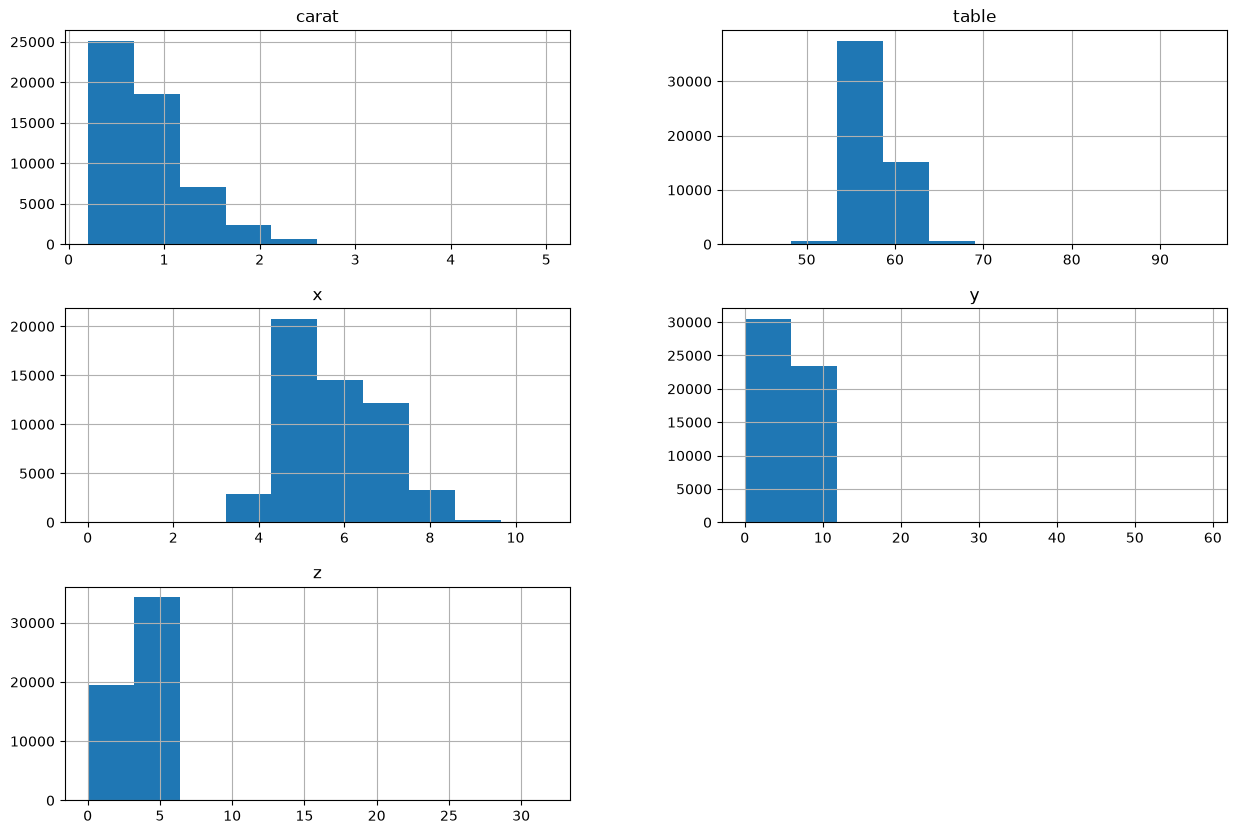

In [19]:
freqgraph.hist(figsize =(15,10))

In [20]:
df["carat"] = df["carat"].fillna(df["carat"].median())
df["table"] = df["table"].fillna(df["table"].median())
df["color"] = df["color"].fillna(df['color'].mode()[0])
df.isnull().sum()


carat      0
cut        0
color      0
clarity    0
table      0
price      0
x          0
y          0
z          0
dtype: int64

In [21]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

In [23]:
df.dtypes

carat      float64
cut            str
color          str
clarity        str
table      float64
price        int64
x          float64
y          float64
z          float64
dtype: object

In [24]:
for i in ["color","cut", "clarity"]:
    df[i] = le.fit_transform(df[i])
df

,carat,cut,color,clarity,table,price,x,y,z
0,0.23,2,1,3,55.0,326,3.95,3.98,2.43
1,0.21,3,1,2,61.0,326,3.89,3.84,2.31
2,0.23,1,1,4,65.0,327,4.05,4.07,2.31
3,0.29,3,5,5,58.0,334,4.20,4.23,2.63
4,0.31,1,6,3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...
53935,0.72,2,0,2,57.0,2757,5.75,5.76,3.50
53936,0.72,1,0,2,55.0,2757,5.69,5.75,3.61
53937,0.70,4,0,2,60.0,2757,5.66,5.68,3.56
53938,0.86,3,4,3,58.0,2757,6.15,6.12,3.74


In [67]:
from sklearn.preprocessing import MinMaxScaler
minmax = MinMaxScaler(feature_range = (0,3))

In [69]:
X = df.drop(["price"], axis =1)
X

,carat,cut,color,clarity,table,x,y,z
0,0.23,2,1,3,55.0,3.95,3.98,2.43
1,0.21,3,1,2,61.0,3.89,3.84,2.31
2,0.23,1,1,4,65.0,4.05,4.07,2.31
3,0.29,3,5,5,58.0,4.20,4.23,2.63
4,0.31,1,6,3,58.0,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...
53935,0.72,2,0,2,57.0,5.75,5.76,3.50
53936,0.72,1,0,2,55.0,5.69,5.75,3.61
53937,0.70,4,0,2,60.0,5.66,5.68,3.56
53938,0.86,3,4,3,58.0,6.15,6.12,3.74


In [70]:
type(X)

pandas.DataFrame

In [71]:
Y = df["price"]
Y

0         326
1         326
2         327
3         334
4         335
         ... 
53935    2757
53936    2757
53937    2757
53938    2757
53939    2757
Name: price, Length: 53940, dtype: int64

In [72]:
X1 = minmax.fit_transform(X)

In [73]:
X1 = pd.DataFrame(X1,columns = X.columns)
X2 = pd.concat([X1,Y], axis =1)
X2.describe()

,carat,cut,color,clarity,table,x,y,z,price
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.372935,1.914753,1.297099,1.643636,0.834068,1.600882,0.292081,0.333928,3932.799722
std,0.295641,0.770781,0.850552,0.739110,0.128913,0.313341,0.058173,0.066403,3989.439738
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,326.000000
25%,0.124740,1.500000,0.500000,0.857143,0.750000,1.315642,0.240407,0.274528,950.000000
50%,0.311850,1.500000,1.500000,1.714286,0.807692,1.592179,0.290832,0.333019,2401.000000
75%,0.523909,2.250000,2.000000,2.142857,0.923077,1.826816,0.333107,0.381132,5324.250000
max,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,18823.000000


In [74]:
X2.to_csv("diamonds_dataset_cleaned.csv")